# Customer Churn Prediction — ML Semester Project
**CS-13410 Introduction to Machine Learning · Fall 2026 · The University of Lahore**

**Group members:** _Name 1 (Roll no.)_, _Name 2 (Roll no.)_, _Name 3 (Roll no.)_, _Name 4 (Roll no.)_

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns) — public dataset published by IBM.

This notebook grows over the semester. Each part of the project adds a new section:
- **Part 1 — Data Preparation & Pipeline** ← this section
- Part 2 — Supervised Learning Baseline
- Part 3 — Ensembles & Hyperparameter Optimisation
- Part 4 — Neural Network, Unsupervised Learning & Interpretability

---
# Part 1 — Data Preparation & Pipeline

## 1.1 Problem framing
| Item | Our choice |
|---|---|
| **Business problem** | A telecom company loses customers ("churn"). If we can predict who is about to leave, the company can offer them a discount or support before they go. |
| **Prediction target** | `Churn` — did the customer leave? (Yes = 1, No = 0) |
| **Task type** | Binary **classification** (two possible answers) |
| **Success metric** | **F1-score** (main) and **ROC-AUC**. We do **not** rely on accuracy because only ~27% of customers churn: a useless model that always says "No" would already be ~73% accurate. F1 rewards a model only if it actually finds the churners. |
| **Why this dataset** | 7,043 rows (> 1,000 required); mix of numeric (tenure, charges) and categorical (contract, payment method, services) features; real data problems to fix (missing values, class imbalance); good for clustering (customer segments) and fairness analysis (gender, senior citizens) in later parts; public, no privacy issues. |

## 1.2 Import libraries
- **pandas** – tables of data (like Excel in Python)
- **numpy** – maths on numbers
- **matplotlib / seaborn** – charts
- **scikit-learn (sklearn)** – the machine-learning toolkit

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed number so everyone gets the same results every time
print("Libraries loaded ✔")

Libraries loaded ✔


## 1.3 Load the dataset
The CSV file should sit in the same folder as this notebook. If it is not found (for example in Google Colab), the code downloads it from IBM's public GitHub page.

In [2]:
FILE = "Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

if os.path.exists(FILE):
    df = pd.read_csv(FILE)
else:
    df = pd.read_csv(URL)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.4 First look at the data

In [3]:
# Column names, data types and how many non-empty values each column has
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Summary statistics of the numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**What we notice:**
- `customerID` is just an ID number — it has no predictive value, so we will drop it.
- `TotalCharges` should be a number, but pandas reads it as **text**. That means some cells are not numbers (they are blank spaces). We fix this next.
- `SeniorCitizen` is already 0/1; most other columns are text categories ("Yes"/"No", "Month-to-month", ...).

## 1.5 Basic cleaning
These steps are **safe to do before splitting** because they don't learn anything from the data — they just fix formats.

In [5]:
# 1) Drop the ID column
df = df.drop(columns=["customerID"])

# 2) Convert TotalCharges from text to numbers. Blank cells become NaN (= missing value)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 3) Convert the target from Yes/No to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Missing values per column (only columns that have some):")
print(df.isna().sum()[df.isna().sum() > 0])

Missing values per column (only columns that have some):
TotalCharges    11
dtype: int64


In [6]:
# Who are the customers with missing TotalCharges?
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


**Finding:** all 11 customers with missing `TotalCharges` have **tenure = 0** — they joined so recently that they haven't been billed yet.
We will **not** fill this in by hand now. Instead, the pipeline will fill it with the median (`SimpleImputer`) **using training data only**, so no information leaks from the test set.

## 1.6 Exploratory Data Analysis (EDA)
### Chart 1 — How many customers churned? (class imbalance)

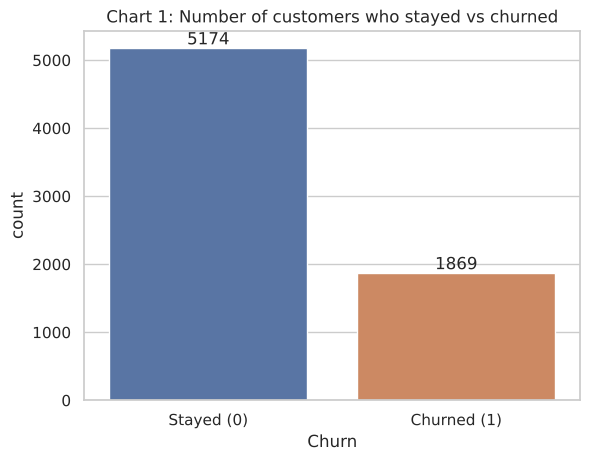

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [7]:
ax = sns.countplot(x="Churn", data=df, hue="Churn", palette=["#4C72B0", "#DD8452"], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
ax.set_title("Chart 1: Number of customers who stayed vs churned")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()
print(df["Churn"].value_counts(normalize=True).round(3))

**Interpretation:** about **73% stayed and 27% churned**. The classes are **imbalanced**, so (a) we use F1/ROC-AUC instead of accuracy, (b) we split with `stratify` so train and test keep the same 73/27 ratio, and (c) we use `class_weight="balanced"` in the model so it pays more attention to the smaller "churned" class.

### Chart 2 — Churn rate by contract type

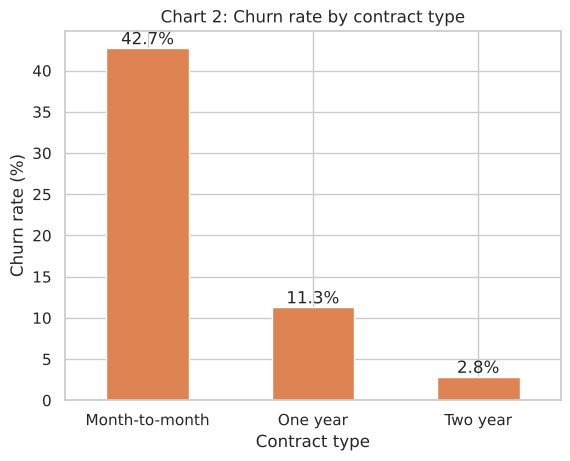

In [8]:
rate = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False) * 100
ax = rate.plot(kind="bar", color="#DD8452")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Contract type")
ax.set_title("Chart 2: Churn rate by contract type")
plt.xticks(rotation=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.show()

**Interpretation:** customers on **month-to-month** contracts churn far more (~43%) than those on one-year (~11%) or two-year (~3%) contracts. Contract type will likely be one of the strongest predictors.

### Chart 3 — Tenure and monthly charges: churned vs stayed

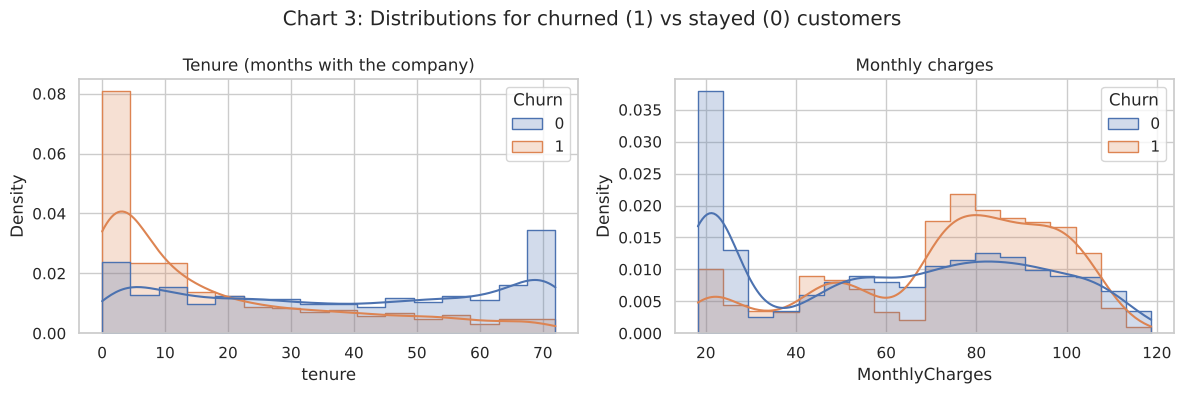

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Tenure (months with the company)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, element="step", stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_title("Monthly charges")
fig.suptitle("Chart 3: Distributions for churned (1) vs stayed (0) customers")
plt.tight_layout(); plt.show()

**Interpretation:** churners are mostly **new customers** (low tenure — many leave in the first few months) and tend to have **higher monthly charges**. Long-term customers rarely leave.

### Chart 4 — Correlation between numeric features

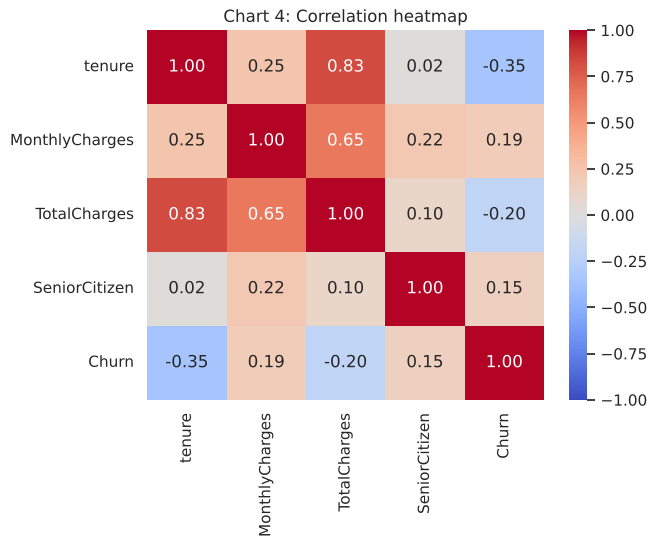

In [10]:
num_for_corr = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]
sns.heatmap(df[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Chart 4: Correlation heatmap")
plt.show()

**Interpretation:** `TotalCharges` is strongly correlated with `tenure` (~0.83) — it is roughly tenure × monthly charges. `tenure` is negatively correlated with churn (longer customers churn less), matching Chart 3.

## 1.7 Outlier check
We use the **IQR rule**: a value is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR (Q1/Q3 = 25th/75th percentile, IQR = Q3 − Q1).

tenure          -> outliers: 0
MonthlyCharges  -> outliers: 0
TotalCharges    -> outliers: 0


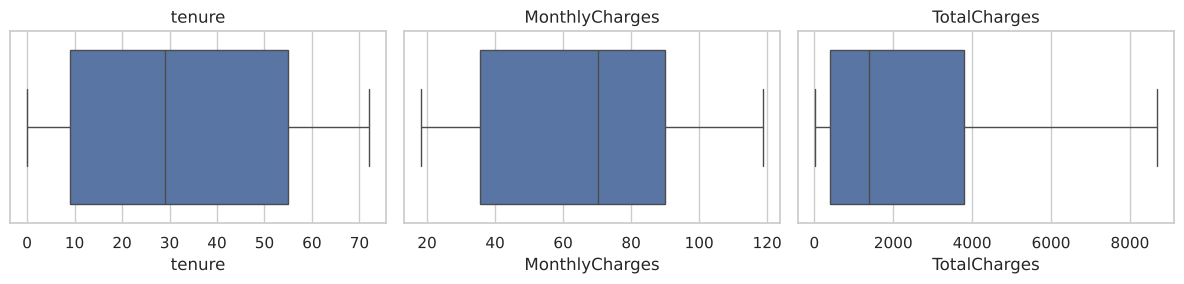

In [11]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:15s} -> outliers: {n_out}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=df[col], ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

**Decision:** there are **no outliers** by the IQR rule. All values are realistic (tenure 0–72 months, charges in a normal range), so we keep every row. `StandardScaler` in the pipeline will put the numeric features on the same scale.

## 1.8 Train / test split — BEFORE any learning step
This is the key to a **leakage-free** pipeline. *Data leakage* means information from the test set sneaks into training (for example, computing the median or scaling using **all** rows). That makes results look better than they really are.

So we split first: 80% training, 20% test. `stratify=y` keeps the 73/27 churn ratio in both parts. The test set is locked away until the very end.

In [12]:
X = df.drop(columns=["Churn"])   # features (inputs)
y = df["Churn"]                  # target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, " churn rate:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, " churn rate:", round(y_test.mean(), 3))

Training set: (5634, 19)  churn rate: 0.265
Test set:     (1409, 19)  churn rate: 0.265


## 1.9 Feature construction
We create two new features that may help the model:
- **`AvgMonthlySpend`** = TotalCharges / (tenure + 1) — the customer's average bill so far (+1 avoids dividing by zero for new customers).
- **`NumServices`** = how many extra services the customer has (online security, backup, tech support, streaming, ...). Customers using more services may be less likely to leave.

We wrap this in a `FunctionTransformer` so it runs **inside** the pipeline. It only uses values from the same row, so it cannot leak test information.

In [13]:
SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def add_features(data):
    data = data.copy()
    data["AvgMonthlySpend"] = data["TotalCharges"] / (data["tenure"] + 1)
    data["NumServices"] = (data[SERVICE_COLS] == "Yes").sum(axis=1)
    return data

feature_maker = FunctionTransformer(add_features)

# quick test on 3 rows
add_features(X_train.head(3))[["tenure", "TotalCharges", "AvgMonthlySpend", "NumServices"]]

,tenure,TotalCharges,AvgMonthlySpend,NumServices
3738,35,1701.65,47.268056,3
3151,15,1151.55,71.971875,2
4860,13,590.35,42.167857,3


## 1.10 Preprocessing with `ColumnTransformer`
Different column types need different treatment:

| Column type | Step 1: fill missing values | Step 2: transform |
|---|---|---|
| **Numeric** | `SimpleImputer(strategy="median")` | `StandardScaler` (mean 0, std 1) |
| **Categorical** | `SimpleImputer(strategy="most_frequent")` | `OneHotEncoder` (turns "Month-to-month / One year / Two year" into 0/1 columns) |

`handle_unknown="ignore"` means that if the test data has a category never seen in training, the code won't crash.

In [14]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend", "NumServices", "SeniorCitizen"]
categorical_features = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                        "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                        "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                        "PaperlessBilling", "PaymentMethod"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 1.11 The full leakage-free pipeline
Everything goes into **one** `Pipeline`: feature construction → preprocessing → model.

When we call `.fit(X_train, y_train)`, every step learns **only from training data** (the median, the scaling mean/std, the list of categories). When we call `.predict(X_test)`, the test data is only *transformed* with what was learned from training — it never influences the learning.

For Part 1 we use a simple **Logistic Regression** just to prove the pipeline works end-to-end. Real model comparison comes in Parts 2–4.
`class_weight="balanced"` handles the class imbalance.

In [15]:
model_pipeline = Pipeline([
    ("features", feature_maker),
    ("preprocess", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f70ffff1440>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDicti

## 1.12 Cross-validation on the training set
5-fold **stratified** cross-validation: the training set is split into 5 parts; the model trains on 4 and is checked on the 5th, five times. Because the *whole pipeline* is re-fitted inside each fold, there is no leakage even inside cross-validation.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(model_pipeline, X_train, y_train, cv=cv, scoring=["f1", "roc_auc", "accuracy"])

print(f"CV F1      : {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}")
print(f"CV ROC-AUC : {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
print(f"CV Accuracy: {scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}")

CV F1      : 0.634 ± 0.019
CV ROC-AUC : 0.849 ± 0.012
CV Accuracy: 0.756 ± 0.012


## 1.13 Final check on the held-out test set

Test F1     : 0.617
Test ROC-AUC: 0.847

              precision    recall  f1-score   support

      Stayed       0.90      0.73      0.81      1035
     Churned       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



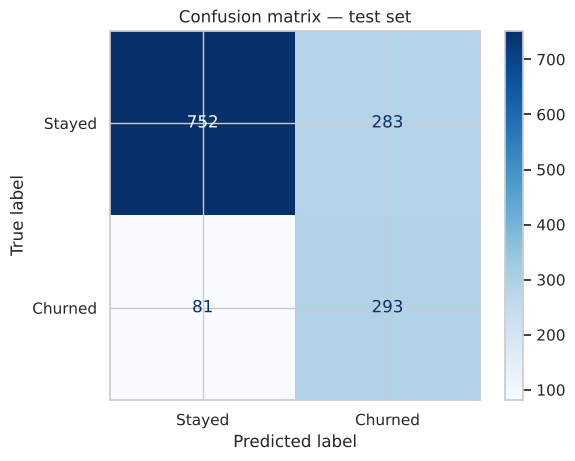

In [17]:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print(f"Test F1     : {f1_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Confusion matrix — test set")
plt.show()

## 1.14 Part 1 summary
- **Problem:** predict customer churn (binary classification); main metric **F1**, also **ROC-AUC**.
- **Cleaning:** dropped `customerID`; converted `TotalCharges` to numeric (11 missing values, all tenure = 0, imputed with the training median inside the pipeline); target mapped to 1/0.
- **Outliers:** none found by the IQR rule — all rows kept.
- **Class imbalance (~27% churn):** stratified split + stratified CV + `class_weight="balanced"` + F1/ROC-AUC instead of accuracy.
- **Feature construction:** `AvgMonthlySpend`, `NumServices`.
- **Encoding / scaling:** One-hot encoding for categorical, standard scaling for numeric, via `ColumnTransformer`.
- **Leakage prevention:** split **before** any fitting; all learning steps live inside one sklearn `Pipeline`, so medians, scaling and categories are learned from training data only — including inside each CV fold.
- **EDA insights:** month-to-month contracts, short tenure and high monthly charges are linked to higher churn.
- **Sanity baseline:** Logistic Regression gives the scores shown above; Part 2 will compare Naive Bayes and Decision Tree using this same pipeline.